In [ ]:
# ==========================================
# 0. IMPORT LIBRARIES & CONFIGURATION
# ==========================================

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pyarrow.parquet as pq
from PIL import Image
from IPython.display import display

# Đường dẫn dataset
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "ICDAR2019-SROIE" / "data"

TRAIN_PATH = DATA_DIR / "train-00000-of-00001.parquet"
TEST_PATH = DATA_DIR / "test-00000-of-00001.parquet"

# Kiểm tra đường dẫn
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)

print("Train file exists:", TRAIN_PATH.exists())
print("Test file exists:", TEST_PATH.exists())

Project directory: /app
Dataset directory: /app/data/ICDAR2019-SROIE/data
Train file exists: True
Test file exists: True


In [22]:
# ==========================================
# 1. LOAD DATASET METADATA
# ==========================================

train_pf = pq.ParquetFile(TRAIN_PATH)
test_pf = pq.ParquetFile(TEST_PATH)

print("TRAIN:", train_pf.metadata.num_rows, "samples")
print("TEST:", test_pf.metadata.num_rows, "samples")
print("TOTAL:", train_pf.metadata.num_rows + test_pf.metadata.num_rows, "samples")

print("\n========== TRAIN SCHEMA ==========")
print(train_pf.schema)

print("\n========== TEST SCHEMA ==========")
print(test_pf.schema)

TRAIN: 626 samples
TEST: 361 samples
TOTAL: 987 samples

========== TRAIN SCHEMA ==========
required group field_id=-1 schema {
  optional group field_id=-1 image {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional binary field_id=-1 key (String);
  optional group field_id=-1 image_size {
    optional int64 field_id=-1 width;
    optional int64 field_id=-1 height;
  }
  optional group field_id=-1 entities {
    optional binary field_id=-1 company (String);
    optional binary field_id=-1 date (String);
    optional binary field_id=-1 address (String);
    optional binary field_id=-1 total (String);
  }
  optional group field_id=-1 words (List) {
    repeated group field_id=-1 list {
      optional binary field_id=-1 element (String);
    }
  }
  optional group field_id=-1 bboxes (List) {
    repeated group field_id=-1 list {
      optional group field_id=-1 element (List) {
        repeated group field_id=-1 list {
          optional i

In [23]:
# ==========================================
# 2. LOAD DATA & BASIC INSPECTION
# ==========================================

# Chỉ đọc các cột cần khảo sát, không đọc bytes ảnh
train_df = pq.read_table(
    TRAIN_PATH,
    columns=["key", "image_size", "entities", "words", "bboxes"]
).to_pandas()

test_df = pq.read_table(
    TEST_PATH,
    columns=["key", "image_size", "entities", "words", "bboxes"]
).to_pandas()

print("TRAIN SHAPE:", train_df.shape)
print("TEST SHAPE:", test_df.shape)

print("\n========== TRAIN SAMPLE ==========")
display(train_df.head(3))

print("\n========== TEST SAMPLE ==========")
display(test_df.head(3))

print("\n========== DATA TYPES ==========")
print(train_df.dtypes)

TRAIN SHAPE: (626, 5)
TEST SHAPE: (361, 5)

========== TRAIN SAMPLE ==========


,key,image_size,entities,words,bboxes
0,X00016469612,"{'width': 463, 'height': 1013}","{'company': 'BOOK TA .K (TAMAN DAYA) SDN BHD',...","[TAN WOON YANN, BOOK TA .K(TAMAN DAYA) SDN BND...","[[72, 25, 326, 64], [50, 82, 440, 121], [205, ..."
1,X00016469619,"{'width': 439, 'height': 1004}","{'company': 'INDAH GIFT & HOME DECO', 'date': ...","[TAN WOON YANN, INDAH GIFT & HOME DECO, 27, TA...","[[76, 50, 323, 84], [110, 165, 315, 188], [126..."
2,X00016469620,"{'width': 459, 'height': 949}","{'company': 'MR D.I.Y. (JOHOR) SDN BHD', 'date...","[TAN WOON YANN, MR D.T.Y. (JOHOR) SDN BHD, (CO...","[[119, 47, 367, 80], [93, 161, 352, 183], [137..."



========== TEST SAMPLE ==========


,key,image_size,entities,words,bboxes
0,X00016469670,"{'width': 463, 'height': 894}","{'company': 'OJC MARKETING SDN BHD', 'date': '...","[TAN CHAY YEE, *** COPY ***, OJC MARKETING SDN...","[[98, 26, 321, 66], [138, 95, 279, 120], [80, ..."
1,X00016469671,"{'width': 463, 'height': 776}","{'company': 'OJC MARKETING SDN BHD', 'date': '...","[TAN CHAY YEE, OJC MARKETING SDN BHD, ROC NO: ...","[[114, 54, 326, 92], [60, 119, 300, 136], [100..."
2,X51005200931,"{'width': 992, 'height': 1403}","{'company': 'PERNIAGAAN ZHENG HUI', 'date': '0...","[PERNIAGAAN ZHENG HUI, JM0326955-V, NO.59 JALA...","[[380, 241, 616, 266], [459, 267, 546, 282], [..."



========== DATA TYPES ==========
key           object
image_size    object
entities      object
words         object
bboxes        object
dtype: object


In [24]:
# ==========================================
# 3. DATA QUALITY CHECK
# ==========================================

# Kiểm tra dữ liệu thiếu
print("========== MISSING VALUES ==========")
print("TRAIN:")
print(train_df.isnull().sum())

print("\nTEST:")
print(test_df.isnull().sum())


# Kiểm tra key bị trùng
print("\n========== DUPLICATE KEYS ==========")
print("Train duplicate keys:", train_df["key"].duplicated().sum())
print("Test duplicate keys:", test_df["key"].duplicated().sum())


# Kiểm tra dữ liệu trùng giữa Train và Test
train_keys = set(train_df["key"])
test_keys = set(test_df["key"])

overlap_keys = train_keys.intersection(test_keys)

print("\n========== TRAIN / TEST OVERLAP ==========")
print("Duplicate keys between Train and Test:", len(overlap_keys))

========== MISSING VALUES ==========
TRAIN:
key           0
image_size    0
entities      0
words         0
bboxes        0
dtype: int64

TEST:
key           0
image_size    0
entities      0
words         0
bboxes        0
dtype: int64

========== DUPLICATE KEYS ==========
Train duplicate keys: 0
Test duplicate keys: 0

========== TRAIN / TEST OVERLAP ==========
Duplicate keys between Train and Test: 0


In [25]:
# ==========================================
# 4. ANALYZE GROUND TRUTH ENTITIES
# ==========================================

ENTITY_FIELDS = ["company", "date", "address", "total"]

# Chuyển entities thành DataFrame để phân tích từng trường
train_entities = pd.json_normalize(train_df["entities"])
test_entities = pd.json_normalize(test_df["entities"])


def analyze_entities(df, dataset_name):
    print(f"\n========== {dataset_name} ENTITIES ==========")

    for field in ENTITY_FIELDS:
        values = df[field]

        missing_count = values.isna().sum()
        empty_count = (
            values.fillna("").astype(str).str.strip().eq("").sum()
        )

        valid_count = len(values) - missing_count - (
            empty_count - missing_count
        )

        print(f"\nField: {field}")
        print("Missing:", missing_count)
        print("Empty:", empty_count - missing_count)
        print("Non-empty:", len(values) - empty_count)


analyze_entities(train_entities, "TRAIN")
analyze_entities(test_entities, "TEST")

print("\n========== TRAIN ENTITY SAMPLES ==========")
display(train_entities.head(5))


========== TRAIN ENTITIES ==========

Field: company
Missing: 0
Empty: 0
Non-empty: 626

Field: date
Missing: 0
Empty: 0
Non-empty: 626

Field: address
Missing: 1
Empty: 0
Non-empty: 625

Field: total
Missing: 0
Empty: 1
Non-empty: 625

========== TEST ENTITIES ==========

Field: company
Missing: 0
Empty: 0
Non-empty: 361

Field: date
Missing: 0
Empty: 0
Non-empty: 361

Field: address
Missing: 0
Empty: 0
Non-empty: 361

Field: total
Missing: 0
Empty: 0
Non-empty: 361

========== TRAIN ENTITY SAMPLES ==========


,company,date,address,total
0,BOOK TA .K (TAMAN DAYA) SDN BHD,25/12/2018,"NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 8...",9.00
1,INDAH GIFT & HOME DECO,19/10/2018,"27, JALAN DEDAP 13, TAMAN JOHOR JAYA, 81100 JO...",60.30
2,MR D.I.Y. (JOHOR) SDN BHD,12-01-19,"LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERI...",33.90
3,YONGFATT ENTERPRISE,25/12/2018,NO 122.124. JALAN DEDAP 13 81100 JOHOR BAHRU,80.90
4,MR D.I.Y. (M) SDN BHD,18-11-18,"LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERI...",30.90


========== TRAIN IMAGE SIZE ==========


,width,height
count,626.00,626.00
mean,1325.75,2355.87
std,1413.78,1841.28
min,436.00,605.00
25%,623.00,1395.50
50%,812.00,1682.50
75%,935.00,2141.00
max,4961.00,7016.00



========== TEST IMAGE SIZE ==========


,width,height
count,361.00,361.00
mean,1430.23,2497.22
std,1508.81,1961.16
min,435.00,776.00
25%,703.00,1407.00
50%,867.00,1735.00
75%,935.00,2216.00
max,4961.00,7016.00



========== ASPECT RATIO ==========


count    626.000
mean       0.514
std        0.120
min        0.263
25%        0.424
50%        0.501
75%        0.581
max        0.971
Name: aspect_ratio, dtype: float64

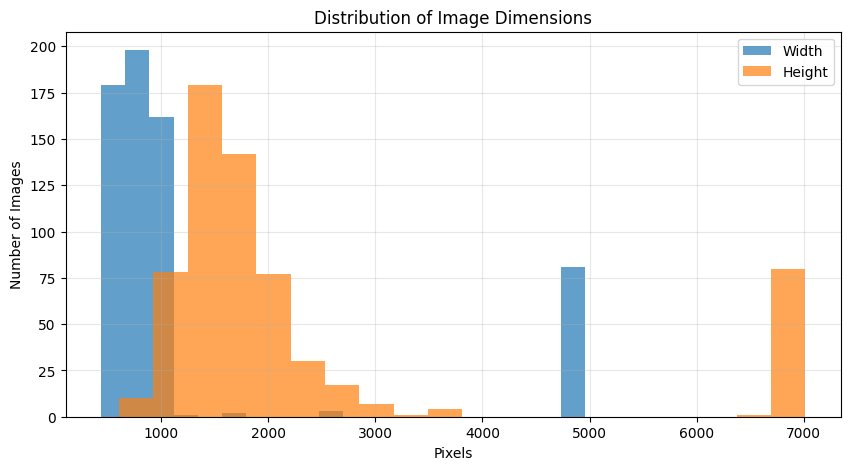

In [26]:
# ==========================================
# 5. IMAGE DIMENSION ANALYSIS
# ==========================================

train_sizes = pd.json_normalize(train_df["image_size"])
test_sizes = pd.json_normalize(test_df["image_size"])

print("========== TRAIN IMAGE SIZE ==========")
display(train_sizes.describe().round(2))

print("\n========== TEST IMAGE SIZE ==========")
display(test_sizes.describe().round(2))

# Tính tỷ lệ chiều rộng / chiều cao
train_sizes["aspect_ratio"] = (
    train_sizes["width"] / train_sizes["height"]
)

print("\n========== ASPECT RATIO ==========")
display(train_sizes["aspect_ratio"].describe().round(3))

# Trực quan hóa kích thước ảnh
plt.figure(figsize=(10, 5))

plt.hist(train_sizes["width"], bins=20, alpha=0.7, label="Width")
plt.hist(train_sizes["height"], bins=20, alpha=0.7, label="Height")

plt.title("Distribution of Image Dimensions")
plt.xlabel("Pixels")
plt.ylabel("Number of Images")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
# ==========================================
# 6. WORDS & BOUNDING BOXES ANALYSIS
# ==========================================

def get_list_length(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return len(value)
    return 0


train_word_counts = train_df["words"].apply(get_list_length)
train_bbox_counts = train_df["bboxes"].apply(get_list_length)

test_word_counts = test_df["words"].apply(get_list_length)
test_bbox_counts = test_df["bboxes"].apply(get_list_length)

print("========== TRAIN WORDS ==========")
print(train_word_counts.describe().round(2))

print("\n========== TRAIN BOUNDING BOXES ==========")
print(train_bbox_counts.describe().round(2))

print("\n========== TEST WORDS ==========")
print(test_word_counts.describe().round(2))

print("\n========== TEST BOUNDING BOXES ==========")
print(test_bbox_counts.describe().round(2))


# Kiểm tra số lượng words và bboxes có khớp nhau không
train_mismatch = (train_word_counts != train_bbox_counts).sum()
test_mismatch = (test_word_counts != test_bbox_counts).sum()

print("\n========== WORDS / BBOXES CONSISTENCY ==========")
print("Train mismatches:", train_mismatch)
print("Test mismatches:", test_mismatch)

========== TRAIN WORDS ==========
count    626.00
mean      53.72
std       17.91
min       18.00
25%       42.00
50%       50.00
75%       63.00
max      153.00
Name: words, dtype: float64

========== TRAIN BOUNDING BOXES ==========
count    626.00
mean      53.72
std       17.91
min       18.00
25%       42.00
50%       50.00
75%       63.00
max      153.00
Name: bboxes, dtype: float64

========== TEST WORDS ==========
count    361.00
mean      53.70
std       17.24
min       23.00
25%       42.00
50%       50.00
75%       63.00
max      121.00
Name: words, dtype: float64

========== TEST BOUNDING BOXES ==========
count    361.00
mean      53.70
std       17.24
min       23.00
25%       42.00
50%       50.00
75%       63.00
max      121.00
Name: bboxes, dtype: float64

========== WORDS / BBOXES CONSISTENCY ==========
Train mismatches: 0
Test mismatches: 0


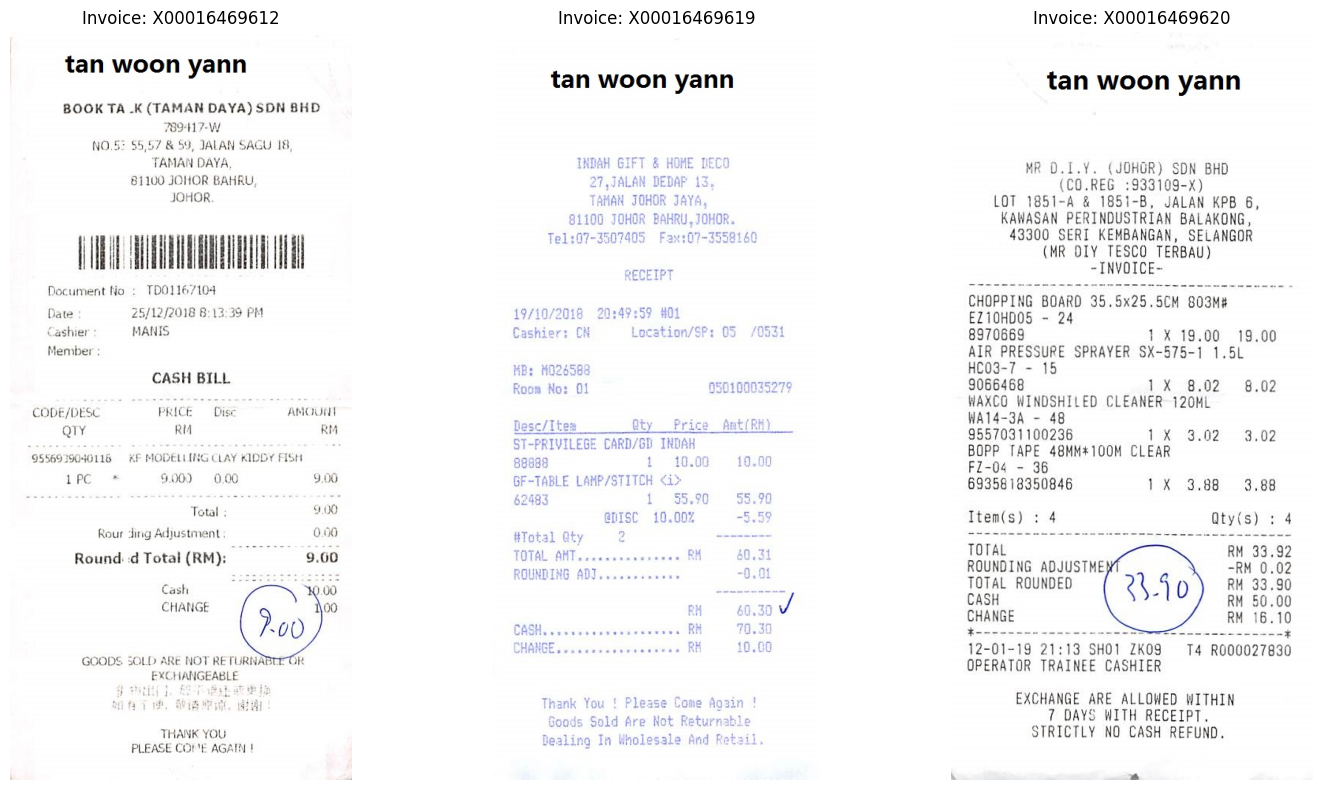

In [13]:
# ==========================================
# 7. VISUALIZE SAMPLE INVOICES
# ==========================================

from io import BytesIO

# Chỉ đọc 3 ảnh đầu tiên
image_table = pq.read_table(
    TRAIN_PATH,
    columns=["image", "key"]
).slice(0, 3)

image_records = image_table.to_pylist()

fig, axes = plt.subplots(1, 3, figsize=(15, 8))

for ax, record in zip(axes, image_records):
    image_bytes = record["image"]["bytes"]

    img = Image.open(BytesIO(image_bytes)).convert("RGB")

    ax.imshow(img)
    ax.set_title(f"Invoice: {record['key']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
# ==========================================
# 8. INSPECT ONE INVOICE
# ==========================================

sample = train_df.iloc[0]

print("========== INVOICE KEY ==========")
print(sample["key"])

print("\n========== GROUND TRUTH ==========")
for field, value in sample["entities"].items():
    print(f"{field}: {value}")

print("\n========== WORDS ==========")
print("Total words:", len(sample["words"]))
print(sample["words"][:30])

print("\n========== BOUNDING BOXES ==========")
print("Total bounding boxes:", len(sample["bboxes"]))
print(sample["bboxes"][:10])

========== INVOICE KEY ==========
X00016469612

========== GROUND TRUTH ==========
company: BOOK TA .K (TAMAN DAYA) SDN BHD
date: 25/12/2018
address: NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.
total: 9.00

========== WORDS ==========
Total words: 44
['TAN WOON YANN' 'BOOK TA .K(TAMAN DAYA) SDN BND' '789417-W' 'NO.53 55'
 'TAMAN DAYA' '81100 JOHOR BAHRU' 'JOHOR.' 'DOCUMENT NO : TD01167104'
 'DATE:' '25/12/2018 8:13:39 PM' 'CASHIER:' 'MANIS' 'MEMBER:' 'CASH BILL'
 'CODE/DESC' 'PRICE' 'DISC' 'AMOUNT' 'QTY' 'RM' 'RM' '9556939040116'
 'KF MODELLING CLAY KIDDY FISH' '1 PC' '*' '9.000' '0.00' '9.00' 'TOTAL:'
 'ROUR DING ADJUSTMENT:']

========== BOUNDING BOXES ==========
Total bounding boxes: 44
[array([ 72,  25, 326,  64]) array([ 50,  82, 440, 121])
 array([205, 121, 285, 139]) array([110, 144, 383, 163])
 array([192, 169, 299, 187]) array([162, 193, 334, 211])
 array([217, 216, 275, 233]) array([ 50, 342, 279, 359])
 array([ 50, 372,  96, 390]) array([165, 372, 

In [32]:
# ==========================================
# 9. CREATE TRAIN / VALIDATION / TEST SPLIT
# ==========================================

RANDOM_SEED = 42

train_keys = train_df["key"].astype(str).to_numpy()
test_keys = test_df["key"].astype(str).to_numpy()

rng = np.random.default_rng(RANDOM_SEED)
shuffled_indices = rng.permutation(len(train_keys))

val_size = int(round(len(train_keys) * 0.2))

val_indices = shuffled_indices[:val_size]
new_train_indices = shuffled_indices[val_size:]

new_train_keys = train_keys[new_train_indices]
val_keys = train_keys[val_indices]

train_split_df = pd.DataFrame({
    "key": new_train_keys,
    "split": "train",
    "source_split": "train"
})

val_split_df = pd.DataFrame({
    "key": val_keys,
    "split": "validation",
    "source_split": "train"
})

test_split_df = pd.DataFrame({
    "key": test_keys,
    "split": "test",
    "source_split": "test"
})

splits_df = pd.concat(
    [train_split_df, val_split_df, test_split_df],
    ignore_index=True
)

SPLIT_PATH = PROJECT_DIR / "splits.csv"
splits_df.to_csv(SPLIT_PATH, index=False)

print("========== SPLIT SUMMARY ==========")
print(splits_df["split"].value_counts())
print("\nTotal samples:", len(splits_df))
print("Saved to:", SPLIT_PATH)

========== SPLIT SUMMARY ==========
split
train         501
test          361
validation    125
Name: count, dtype: int64

Total samples: 987
Saved to: /app/splits.csv


In [35]:

# ==========================================
# 10. VERIFY DATA SPLIT
# ==========================================

train_set = set(
    splits_df.loc[splits_df["split"] == "train", "key"]
)

val_set = set(
    splits_df.loc[splits_df["split"] == "validation", "key"]
)

test_set = set(
    splits_df.loc[splits_df["split"] == "test", "key"]
)

print("========== SPLIT VALIDATION ==========")

print("Total rows:", len(splits_df))
print("Unique keys:", splits_df["key"].nunique())

print("Train:", len(train_set))
print("Validation:", len(val_set))
print("Test:", len(test_set))

print("Train / Validation overlap:", len(train_set & val_set))
print("Train / Test overlap:", len(train_set & test_set))
print("Validation / Test overlap:", len(val_set & test_set))

# Check total records
assert len(splits_df) == 987
assert splits_df["key"].nunique() == 987

# Check split sizes
assert len(train_set) == 501
assert len(val_set) == 125
assert len(test_set) == 361

# Check data leakage
assert len(train_set & val_set) == 0
assert len(train_set & test_set) == 0
assert len(val_set & test_set) == 0

print("\nALL SPLIT CHECKS PASSED!")


========== SPLIT VALIDATION ==========
Total rows: 987
Unique keys: 987
Train: 501
Validation: 125
Test: 361
Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

ALL SPLIT CHECKS PASSED!


In [36]:
# ==========================================
# 11. DATASET SUMMARY
# ==========================================

print("=" * 50)
print("ICDAR2019-SROIE DATASET SUMMARY")
print("=" * 50)

print(f"Total invoices: {len(train_df) + len(test_df)}")
print(f"Original Train: {len(train_df)}")
print(f"Original Test: {len(test_df)}")

print("\nFinal data split:")
print(splits_df["split"].value_counts().to_string())

print("\nEntity fields:", ENTITY_FIELDS)

print("\nTrain missing values:")
print(train_df.isnull().sum().to_string())

print("\nTest missing values:")
print(test_df.isnull().sum().to_string())

print("\nDuplicate keys:", splits_df["key"].duplicated().sum())

print("\nSplit file:", SPLIT_PATH)
print("=" * 50)

ICDAR2019-SROIE DATASET SUMMARY
Total invoices: 987
Original Train: 626
Original Test: 361

Final data split:
split
train         501
test          361
validation    125

Entity fields: ['company', 'date', 'address', 'total']

Train missing values:
key           0
image_size    0
entities      0
words         0
bboxes        0

Test missing values:
key           0
image_size    0
entities      0
words         0
bboxes        0

Duplicate keys: 0

Split file: /app/splits.csv


In [37]:
# 12 
import pandas as pd
import json
from pathlib import Path

# Đọc file phân chia dữ liệu
splits_df = pd.read_csv("/app/splits.csv")

# Kết hợp dữ liệu Train gốc
original_train_df = train_df.copy()

# Tách 4 trường Ground Truth từ entities
gt_df = pd.json_normalize(original_train_df["entities"])

# Ghép key vào Ground Truth
gt_df.insert(0, "key", original_train_df["key"].values)

# Ghép thông tin split
gt_df = gt_df.merge(
    splits_df[["key", "split"]],
    on="key",
    how="left",
    validate="one_to_one"
)

# Kiểm tra không thiếu split
assert gt_df["split"].notna().all()

# Tách Train và Validation
train_gt = gt_df[gt_df["split"] == "train"].copy()
val_gt = gt_df[gt_df["split"] == "validation"].copy()

# Chỉ giữ key và 4 trường cần trích xuất
columns = ["key", "company", "date", "address", "total"]

train_gt = train_gt[columns]
val_gt = val_gt[columns]

# Tạo thư mục lưu
output_dir = Path("/app/outputs/ground_truth")
output_dir.mkdir(parents=True, exist_ok=True)

# Xuất CSV
train_gt.to_csv(
    output_dir / "train_ground_truth.csv",
    index=False
)

val_gt.to_csv(
    output_dir / "validation_ground_truth.csv",
    index=False
)

print("TRAIN GROUND TRUTH:", train_gt.shape)
print("VALIDATION GROUND TRUTH:", val_gt.shape)

print("\nTRAIN SAMPLE:")
display(train_gt.head())

print("\nVALIDATION SAMPLE:")
display(val_gt.head())


TRAIN GROUND TRUTH: (501, 5)
VALIDATION GROUND TRUTH: (125, 5)

TRAIN SAMPLE:


,key,company,date,address,total
0,X00016469612,BOOK TA .K (TAMAN DAYA) SDN BHD,25/12/2018,"NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 8...",9.00
1,X00016469619,INDAH GIFT & HOME DECO,19/10/2018,"27, JALAN DEDAP 13, TAMAN JOHOR JAYA, 81100 JO...",60.30
2,X00016469620,MR D.I.Y. (JOHOR) SDN BHD,12-01-19,"LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERI...",33.90
3,X00016469622,YONGFATT ENTERPRISE,25/12/2018,NO 122.124. JALAN DEDAP 13 81100 JOHOR BAHRU,80.90
4,X00016469623,MR D.I.Y. (M) SDN BHD,18-11-18,"LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERI...",30.90



VALIDATION SAMPLE:


,key,company,date,address,total
6,X00016469672,SOON HUAT MACHINERY ENTERPRISE,11/01/2019,"NO.53 JALAN PUTRA 1, TAMAN SRI PUTRA, 81200 JO...",327.00
14,X51005268472,ASIA MART,22/12/2017,"NO.23 BATU 10, TAMAN SENTOSA, JALAN KAPAR, 422...",32.70
20,X51005337872,SYL ROASTED DELIGHTS SDN. BHD.,06/03/2018,"75. JALAN SS 22/19, DAMANSARA JAYA, 47400 PJ",54.50
28,X51005361950,99 SPEED MART S/B,24-01-18,"LOT P.T. 2811, JALAN ANGSA, TAMAN BERKELEY 411...",2.50
29,X51005365179,C W KHOO HARDWARE SDN BHD,01-03-18,"NO.50,JALAN PBS 14/11, KAWASAN PERINDUSTRIAN B...",21.20
